# Analizando una Imagen

Checkpoint 3 — David Ríos Cortes. Se revisaron y ejecutaron todas las celdas con asistencia de IA mediante IPython en proceso dentro de un entorno virtual del asistente; el kernel Jupyter separado no estuvo disponible. Se agregó la importación de Pandas que faltaba y se conservaron los ejercicios del repositorio.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5, 3.6), "figure.dpi": 65})
img = plt.imread("beagle.jpg")
print("Forma:", img.shape)
print("Tipo:", img.dtype)
print("Píxel [10,10]:", img[10,10])

Forma: (1024, 1024, 3)
Tipo: uint8
Píxel [10,10]: [22 35  5]


In [2]:
rojo = img[10, 10, 0]
verde = img[10, 10, 1]
azul = img[10, 10, 2]

print("Rojo:", rojo)
print("Verde:", verde)
print("Azul:", azul)

Rojo: 22
Verde: 35
Azul: 5


Dimensiones: (1024, 1024, 3)
Píxel [10,10]: [22 35  5]


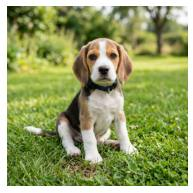

In [3]:
print("Dimensiones:", img.shape)
print("Píxel [10,10]:", img[10,10])

plt.imshow(img)
plt.axis("off")
plt.show()

In [4]:
print("Valor mínimo:", img.min())
print("Valor máximo:", img.max())
print("Media:", img.mean())
print("Desviación estándar:", img.std())

Valor mínimo: 0
Valor máximo: 255
Media: 119.40487066904704
Desviación estándar: 60.935034798738684


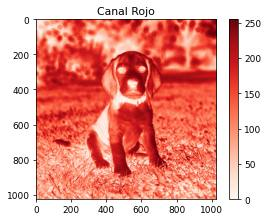

In [5]:
plt.imshow(img[:, :, 0], cmap="Reds")
plt.colorbar()
plt.title("Canal Rojo")
plt.show()

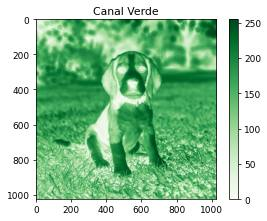

In [6]:
plt.imshow(img[:, :, 1], cmap="Greens")
plt.colorbar()
plt.title("Canal Verde")
plt.show()

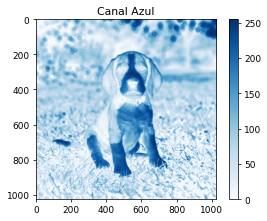

In [7]:
plt.imshow(img[:, :, 2], cmap="Blues")
plt.colorbar()
plt.title("Canal Azul")
plt.show()

In [8]:
media_rojo = img[:, :, 0].mean()
media_verde = img[:, :, 1].mean()
media_azul = img[:, :, 2].mean()

print("Rojo:", media_rojo)
print("Verde:", media_verde)
print("Azul:", media_azul)

Rojo: 133.204363822937
Verde: 145.15760898590088
Azul: 79.85263919830322


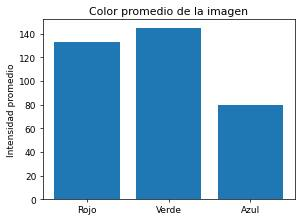

In [9]:
canales = ["Rojo", "Verde", "Azul"]
valores = [media_rojo, media_verde, media_azul]

plt.bar(canales, valores)
plt.ylabel("Intensidad promedio")
plt.title("Color promedio de la imagen")
plt.show()

In [10]:
datos = img.reshape(-1, 3)

df = pd.DataFrame(
    datos,
    columns=["Rojo", "Verde", "Azul"]
)

print(df.head())

   Rojo  Verde  Azul
0    29     46    10
1    27     44     8
2    30     45    12
3    28     43    10
4    29     43     8


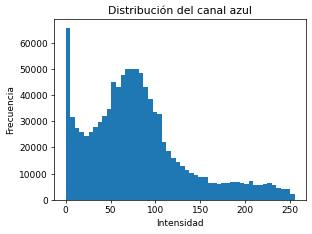

In [11]:
plt.hist(img[:,:,2].ravel(), bins=50)
plt.title("Distribución del canal azul")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")
plt.show()

## Comprobación y conclusión
La imagen tiene filas, columnas y tres canales RGB. Cada píxel se representa con tres intensidades. Al reorganizarla con reshape, cada fila del DataFrame corresponde a un píxel; no cambia su color. Las gráficas de canales usan mapas de color para mostrar intensidad y no son la foto original.

In [12]:
assert img.ndim == 3 and img.shape[2] == 3
assert img.dtype == np.uint8
assert 0 <= int(img.min()) <= int(img.max()) <= 255
assert df.shape == (img.shape[0] * img.shape[1], 3)
assert np.array_equal(df.to_numpy().reshape(img.shape), img)
assert np.allclose(img.mean(axis=(0,1)), [media_rojo, media_verde, media_azul])
print("Comprobado: RGB, rango 0–255, medias por canal y reconstrucción sin pérdida.")

Comprobado: RGB, rango 0–255, medias por canal y reconstrucción sin pérdida.
